In [ ]:
import os
import sys
import subprocess
from pathlib import Path

PROJECT = Path.cwd() / "quickstart-pytorch"
FLWR = Path(sys.prefix) / "Scripts" / "flwr.exe"


assert PROJECT.is_dir(), f"Project not found: {PROJECT}"
assert FLWR.exists(), f"Flower not found: {FLWR}"

env = os.environ.copy()
env["FLWR_HOME"] = str(Path.home() / ".flwr_dv2607_terminal")
env["FLWR_LOCAL_SUPERLINK_HTTP_API_PORT"] = "39125"
env["FLWR_DISABLE_RUNTIME_DEPENDENCY_INSTALLATION"] = "1"

num_attackers = 1
num_rounds = 2

log_path = PROJECT / f"attack{num_attackers}_test.log"

with open(log_path, "w", encoding="utf-8") as log:
    process = subprocess.Popen(
        [
            str(FLWR),
            "run", ".",
            "--federation-config", "num-supernodes=5",
            "--run-config",
            f"num-server-rounds={num_rounds} num-attacked-clients={num_attackers}",
            "--stream"
        ],
        cwd=PROJECT,
        env=env,
        stdout=log,
        stderr=subprocess.STDOUT,
    )

print(f"Flower started, PID: {process.pid}")
print(f"Log: {log_path}")

Flower started, PID: 11160
Log: c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\quickstart-pytorch\attack1_test.log


In [4]:
status = process.poll()

print("Running" if status is None else f"Finished, exit code: {status}")

print("\n".join(
    log_path.read_text(encoding="utf-8", errors="replace").splitlines()[-20:]
))

Running
(raylet)   File "c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\ray\_private\worker.py", line 2801 in disconnect
(raylet)   File "c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\ray\_private\worker.py", line 2132 in shutdown
(raylet)   File "c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\ray\_private\worker.py", line 1143 in wrapper
(pid=3964) 2026-10-25 13:15:22.131309: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
(pid=3964) AttributeError: 'MessageFactory' object has no attribute 'GetProto

In [5]:
import sys
from pathlib import Path

# Locate Flower project
PROJECT = Path.cwd() / "quickstart-pytorch"
sys.path.insert(0, str(PROJECT))

from pytorchexample.task import load_data

# Load data for Client 0
trainloader, testloader = load_data(
    partition_id=0,
    num_partitions=5,
    batch_size=32
)

print("Training batches:", len(trainloader))

c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training batches: 250


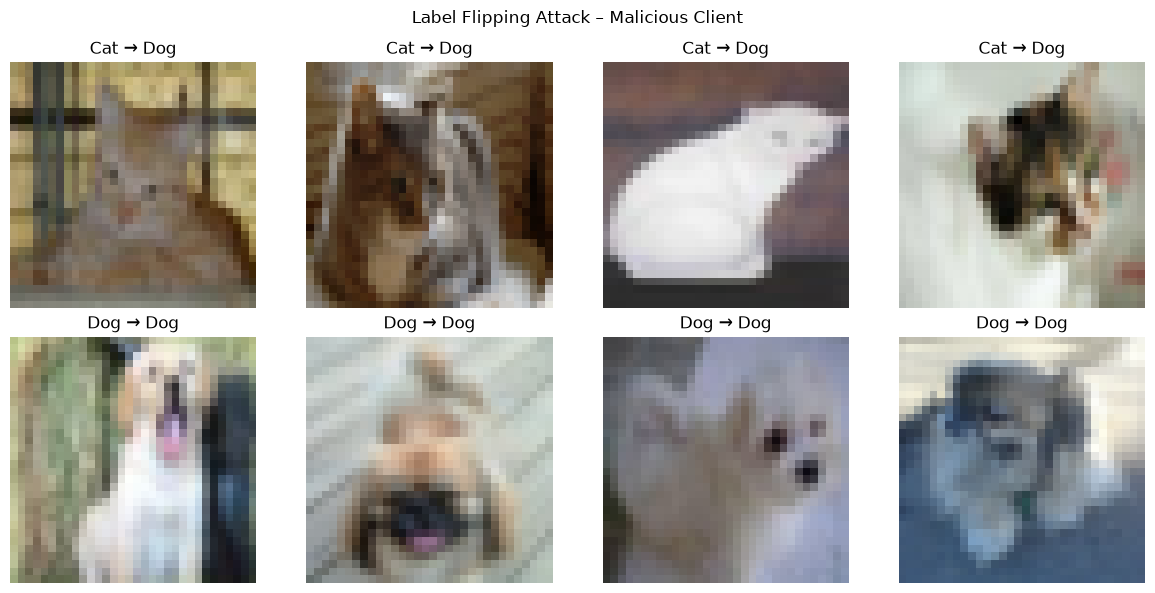

In [7]:
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]


samples = {3: [], 5: []}

# Collect four cats and four dogs
for batch in trainloader:
    images = batch["img"]
    labels = batch["label"]

    for image, label in zip(images, labels):
        label = int(label)

        if label in samples and len(samples[label]) < 4:
            samples[label].append((image, label))

    if all(len(v) == 4 for v in samples.values()):
        break

# Visualize
fig, axs = plt.subplots(2, 4, figsize=(12, 6))

for row, class_id in enumerate([3, 5]):
    for col, (image, label) in enumerate(samples[class_id]):

        image = image.permute(1, 2, 0).numpy()
        image = np.clip(image / 2 + 0.5, 0, 1)

        # Current attack: cyclic label flipping
        # attacked_label = (label + 1) % 10
        attacked_label = 5 if label == 3 else label

        ax = axs[row, col]
        ax.imshow(image)
        ax.set_title(
            f"{class_names[label]} → {class_names[attacked_label]}"
        )
        ax.axis("off")

plt.suptitle("Label Flipping Attack – Malicious Client")
plt.tight_layout()
plt.show()

In [8]:
import torch
import sys
from pathlib import Path

PROJECT = Path.cwd() / "quickstart-pytorch"
sys.path.insert(0, str(PROJECT))

from pytorchexample.task import Net

model_path = (
    Path.home() / "flower_results"
    / "baseline_fedavg_attack1_rounds35.pt"
)

model = Net()

model.load_state_dict(
    torch.load(model_path, map_location="cpu", weights_only=True)
)

model.eval()

print("Trained model loaded!")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\rasmu\\flower_results\\baseline_fedavg_attack1_rounds35.pt'